# Aftershock v1
Forecasting how bumpy the S&P 500 will be over the next five trading days.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import lightgbm
import yfinance as yf

for lib in [pd, np, sklearn, lightgbm, yf]:
    print(lib.__name__, lib.__version__)

pandas 2.2.3
numpy 2.1.3
sklearn 1.6.1
lightgbm 4.6.0
yfinance 0.2.66


## 1. Get the data
Download SPY’s daily adjusted closing prices from January 29, 1993 onward.

In [2]:
raw = yf.download(
    "SPY",
    start="1993-01-29",
    auto_adjust=True,
    progress=False
)

prices = raw["Close"].squeeze().dropna()
prices.name = "price"

print(prices.head())
print(prices.tail())
print("Rows:", len(prices))
print("Missing values:", prices.isna().sum())

Date
1993-01-29    24.053526
1993-02-01    24.224609
1993-02-02    24.275940
1993-02-03    24.532545
1993-02-04    24.635181
Name: price, dtype: float64
Date
2026-09-28    765.609985
2026-09-29    764.200012
2026-09-30    762.630005
2026-10-01    763.989990
2026-10-02    769.640015
Name: price, dtype: float64
Rows: 8477
Missing values: 0


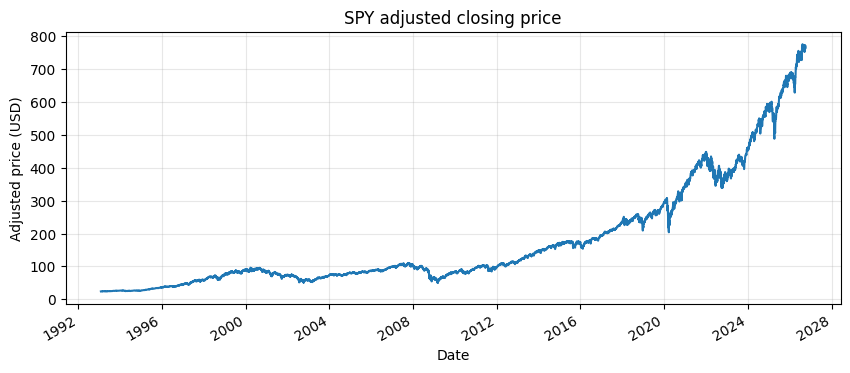

In [3]:
prices.plot(
    title="SPY adjusted closing price",
    figsize=(10, 4)
)
plt.ylabel("Adjusted price (USD)")
plt.xlabel("Date")
plt.grid(alpha=0.3)
plt.show()

## 2. Returns and target
Calculate daily log returns and annualized volatility over the next five trading days.

In [4]:
H = 5  # next five trading days

df = pd.DataFrame({"price": prices})
df["r"] = np.log(df["price"] / df["price"].shift(1))
df["r2"] = df["r"] ** 2

future_sum = df["r2"].rolling(H).sum().shift(-H)
df["target_vol"] = np.sqrt(252 / H * future_sum)
df["target"] = np.log(df["target_vol"])

In [5]:
i = 100

by_hand = np.sqrt(
    252 / H * df["r"].iloc[i + 1:i + 1 + H].pow(2).sum()
)
calculated = df["target_vol"].iloc[i]

print("By hand:", by_hand)
print("Calculated:", calculated)
print("Match:", np.isclose(by_hand, calculated))
print("Last five targets:")
print(df["target_vol"].tail(H))

assert np.isclose(by_hand, calculated)
assert df["target_vol"].tail(H).isna().all()

By hand: 0.12801090598770568
Calculated: 0.12801090598770568
Match: True
Last five targets:
Date
2026-09-28   NaN
2026-09-29   NaN
2026-09-30   NaN
2026-10-01   NaN
2026-10-02   NaN
Name: target_vol, dtype: float64


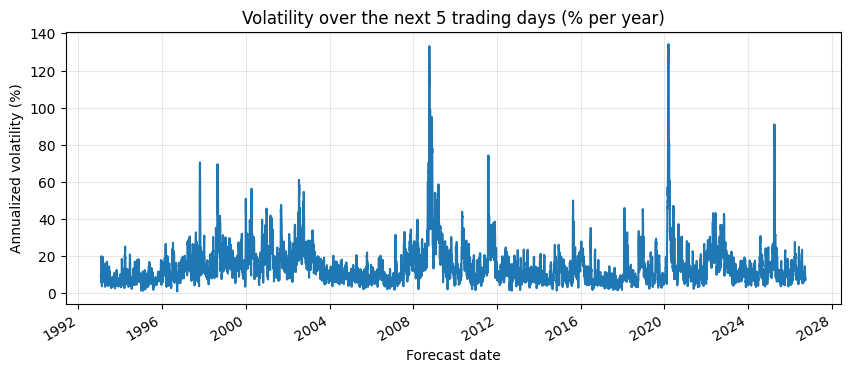

Average: 15.0 %


In [6]:
(df["target_vol"] * 100).plot(
    title="Volatility over the next 5 trading days (% per year)",
    figsize=(10, 4)
)
plt.ylabel("Annualized volatility (%)")
plt.xlabel("Forecast date")
plt.grid(alpha=0.3)
plt.show()

print("Average:", round(df["target_vol"].mean() * 100, 1), "%")

## 3. Inputs
Build daily, weekly, and monthly log-volatility inputs plus today's return, using only current and past data.

In [7]:
def past_vol(n):
    return np.sqrt(252 / n * df["r2"].rolling(n).sum())

TINY = 1e-4

df["vol_1d"] = np.log(past_vol(1).clip(lower=TINY))
df["vol_5d"] = np.log(past_vol(5).clip(lower=TINY))
df["vol_22d"] = np.log(past_vol(22).clip(lower=TINY))
df["ret_1d"] = df["r"]

FEATURES = ["vol_1d", "vol_5d", "vol_22d", "ret_1d"]

data = df.dropna(subset=FEATURES + ["target"]).copy()

print("Rows left:", len(data))
print("Missing values:", data.isna().sum().sum())
print(data[FEATURES + ["target"]].describe().round(3))

assert not data.isna().any().any()
assert np.isfinite(data[FEATURES + ["target"]].to_numpy()).all()

Rows left: 8450
Missing values: 0
         vol_1d    vol_5d   vol_22d    ret_1d    target
count  8450.000  8450.000  8450.000  8450.000  8450.000
mean     -2.691    -2.090    -1.975     0.000    -2.090
std       1.320     0.612     0.484     0.012     0.612
min      -9.210    -4.711    -3.291    -0.116    -4.711
25%      -3.342    -2.502    -2.323    -0.004    -2.503
50%      -2.470    -2.096    -2.021     0.001    -2.096
75%      -1.805    -1.686    -1.659     0.006    -1.687
max       0.766     0.294    -0.069     0.136     0.294


In [8]:
test = df.copy()
test.iloc[200, test.columns.get_loc("r2")] *= 10

checks = []

for n in [1, 5, 22]:
    before = np.log(
        np.sqrt(252 / n * df["r2"].rolling(n).sum())
        .clip(lower=TINY)
    ).iloc[199]

    after = np.log(
        np.sqrt(252 / n * test["r2"].rolling(n).sum())
        .clip(lower=TINY)
    ).iloc[199]

    unchanged = np.isclose(before, after)
    checks.append(unchanged)
    print(f"vol_{n}d on day 199 unchanged:", unchanged)

return_unchanged = (
    df["r"].iloc[199] == test["r"].iloc[199]
)
print("ret_1d on day 199 unchanged:", return_unchanged)

assert all(checks) and return_unchanged

vol_1d on day 199 unchanged: True
vol_5d on day 199 unchanged: True
vol_22d on day 199 unchanged: True
ret_1d on day 199 unchanged: True


## 4. Models
Define Naive, HAR, and LightGBM models that predict log-volatility.

In [9]:
from sklearn.linear_model import LinearRegression
from lightgbm import LGBMRegressor

class Naive:
    def fit(self, X, y):
        return self

    def predict(self, X):
        return X["vol_5d"].values

class HAR:
    cols = ["vol_1d", "vol_5d", "vol_22d"]

    def fit(self, X, y):
        self.model = LinearRegression().fit(X[self.cols], y)
        return self

    def predict(self, X):
        return self.model.predict(X[self.cols])

class LGBM:
    def fit(self, X, y):
        self.model = LGBMRegressor(
            n_estimators=300,
            learning_rate=0.03,
            num_leaves=15,
            random_state=42,
            verbose=-1
        )
        self.model.fit(X[FEATURES], y)
        return self

    def predict(self, X):
        return self.model.predict(X[FEATURES])

MODELS = {"Naive": Naive, "HAR": HAR, "LightGBM": LGBM}

In [10]:
half = len(data) // 2
X, y = data[FEATURES], data["target"]

for name, Model in MODELS.items():
    m = Model().fit(
        X.iloc[:half - H],
        y.iloc[:half - H]
    )

    predictions = m.predict(X.iloc[half:half + 3])

    assert len(predictions) == 3
    assert np.isfinite(predictions).all()

    print(name, predictions.round(3))

Naive [-2.248 -2.218 -2.287]
HAR [-2.046 -2.045 -2.153]
LightGBM [-1.921 -2.107 -2.114]


## 5. Walk-forward test
Retrain annually using past data, with a five-trading-day gap to prevent target leakage.

In [11]:
results = []

for year in range(2005, data.index[-1].year + 1):
    test_rows = data[data.index.year == year]

    if len(test_rows) == 0:
        continue

    T = test_rows.index[0]
    pos_T = data.index.get_loc(T)

    assert pos_T > H, f"Not enough training history in {year}"
    train_rows = data.iloc[:pos_T - H]

    # Latest training target must finish before the test year starts.
    last_train_day = train_rows.index[-1]
    target_end_day = df.index[
        df.index.get_loc(last_train_day) + H
    ]

    assert target_end_day < T, f"Target leakage in {year}"

    out = pd.DataFrame(
        {"actual": test_rows["target"]},
        index=test_rows.index
    )

    for name, Model in MODELS.items():
        m = Model().fit(
            train_rows[FEATURES],
            train_rows["target"]
        )
        out[name] = m.predict(test_rows[FEATURES])

    results.append(out)

    print(
        year,
        "train rows:", len(train_rows),
        "test rows:", len(test_rows),
        "gap check: PASS"
    )

preds = pd.concat(results)

2005 train rows: 2978 test rows: 252 gap check: PASS
2006 train rows: 3230 test rows: 251 gap check: PASS
2007 train rows: 3481 test rows: 251 gap check: PASS
2008 train rows: 3732 test rows: 253 gap check: PASS
2009 train rows: 3985 test rows: 252 gap check: PASS
2010 train rows: 4237 test rows: 252 gap check: PASS
2011 train rows: 4489 test rows: 252 gap check: PASS
2012 train rows: 4741 test rows: 250 gap check: PASS
2013 train rows: 4991 test rows: 252 gap check: PASS
2014 train rows: 5243 test rows: 252 gap check: PASS
2015 train rows: 5495 test rows: 252 gap check: PASS
2016 train rows: 5747 test rows: 252 gap check: PASS
2017 train rows: 5999 test rows: 251 gap check: PASS
2018 train rows: 6250 test rows: 251 gap check: PASS
2019 train rows: 6501 test rows: 252 gap check: PASS
2020 train rows: 6753 test rows: 253 gap check: PASS
2021 train rows: 7006 test rows: 252 gap check: PASS
2022 train rows: 7258 test rows: 251 gap check: PASS
2023 train rows: 7509 test rows: 250 gap check

In [12]:
preds_pct = np.exp(preds) * 100

assert list(preds_pct.columns) == [
    "actual", "Naive", "HAR", "LightGBM"
]
assert np.isfinite(preds_pct.to_numpy()).all()
assert preds_pct.index.is_unique

print(preds_pct.head().round(3))
print("\nColumns:", preds_pct.columns.tolist())
print("Total test rows:", len(preds_pct))
print("First forecast date:", preds_pct.index.min().date())
print("Last forecast date:", preds_pct.index.max().date())
print("Missing values:", preds_pct.isna().sum().sum())

            actual   Naive    HAR  LightGBM
Date                                       
2005-01-03  11.205   5.616  7.010     8.622
2005-01-04   8.572   9.628  8.521     8.947
2005-01-05   7.401  10.759  8.876     7.698
2005-01-06   8.628  11.265  9.046     6.230
2005-01-07   9.345  11.208  8.553     4.941

Columns: ['actual', 'Naive', 'HAR', 'LightGBM']
Total test rows: 5467
First forecast date: 2005-01-03
Last forecast date: 2026-09-25
Missing values: 0


## 6. Results
Compare average prediction errors in percentage points. Lower MAE is better.

In [13]:
scores = {}

for name in MODELS:
    scores[name] = (
        preds_pct[name] - preds_pct["actual"]
    ).abs().mean()

score_table = pd.Series(scores).sort_values()

print("Average error (percentage points):")
print(score_table.round(2))

Average error (percentage points):
HAR         5.12
LightGBM    5.20
Naive       5.86
dtype: float64


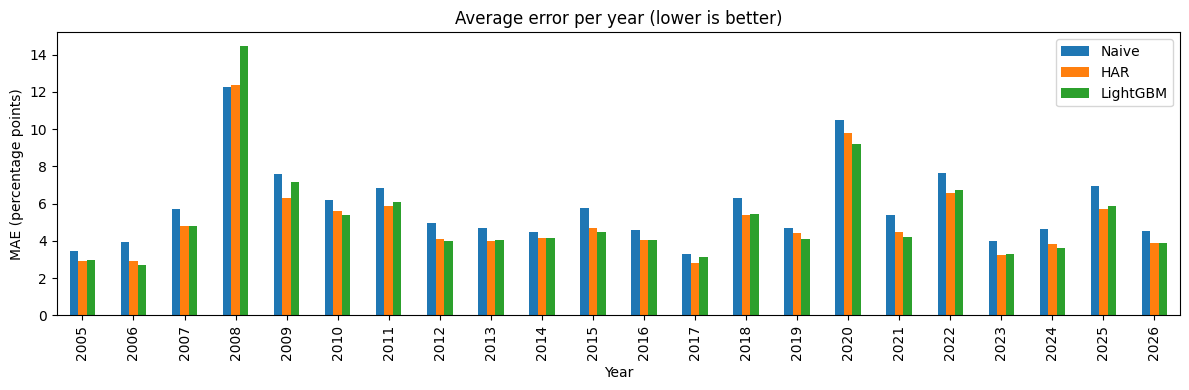

In [14]:
errors = preds_pct[list(MODELS)].sub(
    preds_pct["actual"], axis=0
).abs()

yearly = errors.groupby(errors.index.year).mean()

yearly.plot(
    kind="bar",
    figsize=(12, 4),
    title="Average error per year (lower is better)"
)
plt.ylabel("MAE (percentage points)")
plt.xlabel("Year")
plt.tight_layout()
plt.show()

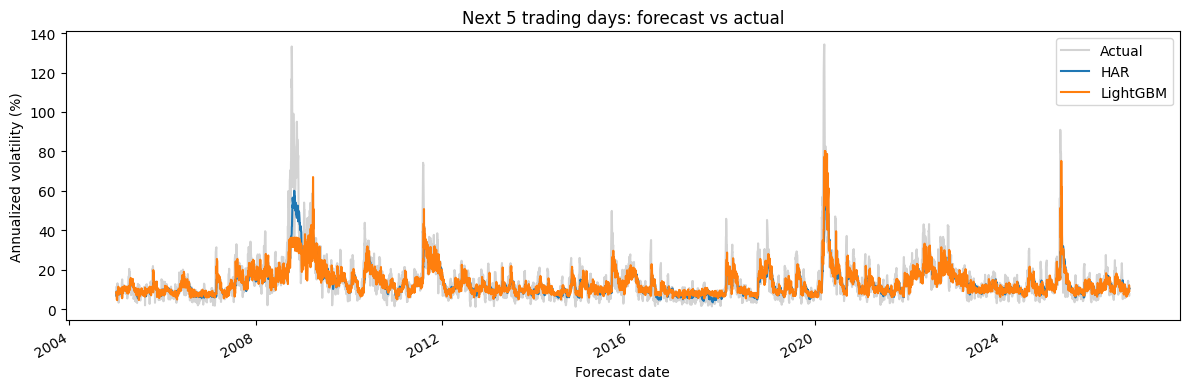

In [15]:
ax = preds_pct["actual"].plot(
    figsize=(12, 4),
    color="lightgray",
    label="Actual"
)

preds_pct[["HAR", "LightGBM"]].plot(ax=ax)

ax.set_title("Next 5 trading days: forecast vs actual")
ax.set_ylabel("Annualized volatility (%)")
ax.set_xlabel("Forecast date")
ax.legend()
plt.tight_layout()
plt.show()

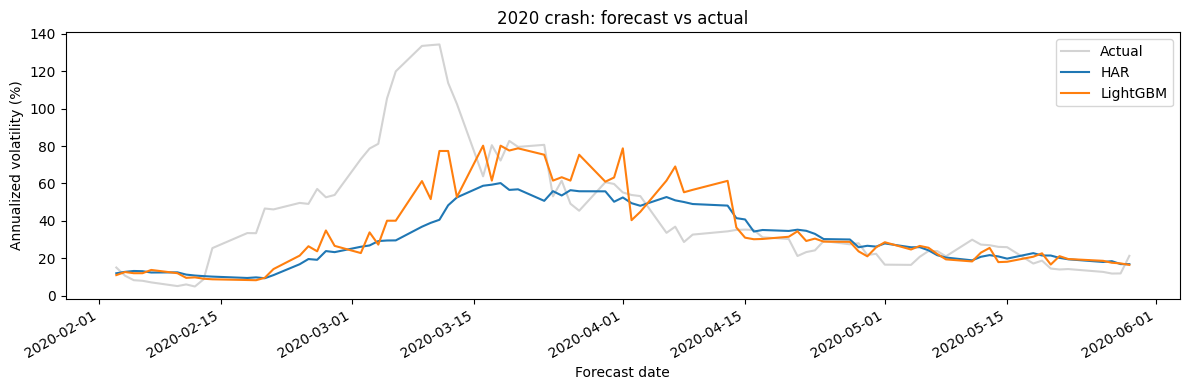

In [16]:
zoom = preds_pct.loc["2020-02":"2020-05"]

ax = zoom["actual"].plot(
    figsize=(12, 4),
    color="lightgray",
    label="Actual"
)

zoom[["HAR", "LightGBM"]].plot(ax=ax)

ax.set_title("2020 crash: forecast vs actual")
ax.set_ylabel("Annualized volatility (%)")
ax.set_xlabel("Forecast date")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Conclusion

HAR had the lowest average error at 5.12 percentage points, compared with 5.20 for LightGBM and 5.86 for Naive. LightGBM did not beat HAR; the simple formula performed slightly better, by approximately 0.08 percentage points. The yearly chart shows that 2008 and 2020 were the hardest years for all three models. I learned how to build volatility forecasts and why separating future targets from training data is essential for an honest test. These results describe this historical test and do not prove that HAR will always outperform LightGBM.